In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score, precision_recall_curve, auc
from imblearn.over_sampling import SMOTE
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import label_binarize
import warnings
warnings.filterwarnings('ignore')

# Set random state for reproducibility
RANDOM_STATE = 42

In [ ]:
# Step 1: Load the dataset
df = pd.read_csv('/content/Final_Augmented_dataset_Diseases_and_Symptoms.csv')
print(f"Original dataset shape: {df.shape}")

Original dataset shape: (246945, 378)



--- EDA Section ---
Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 246945 entries, 0 to 246944
Columns: 378 entries, diseases to neck weakness
dtypes: int64(377), object(1)
memory usage: 712.2+ MB
None

Missing values per column (top 10):
neck weakness                       0
diseases                            0
anxiety and nervousness             0
depression                          0
shortness of breath                 0
depressive or psychotic symptoms    0
sharp chest pain                    0
dizziness                           0
insomnia                            0
abnormal involuntary movements      0
dtype: int64

Number of unique diseases (classes): 773
Total samples: 246945


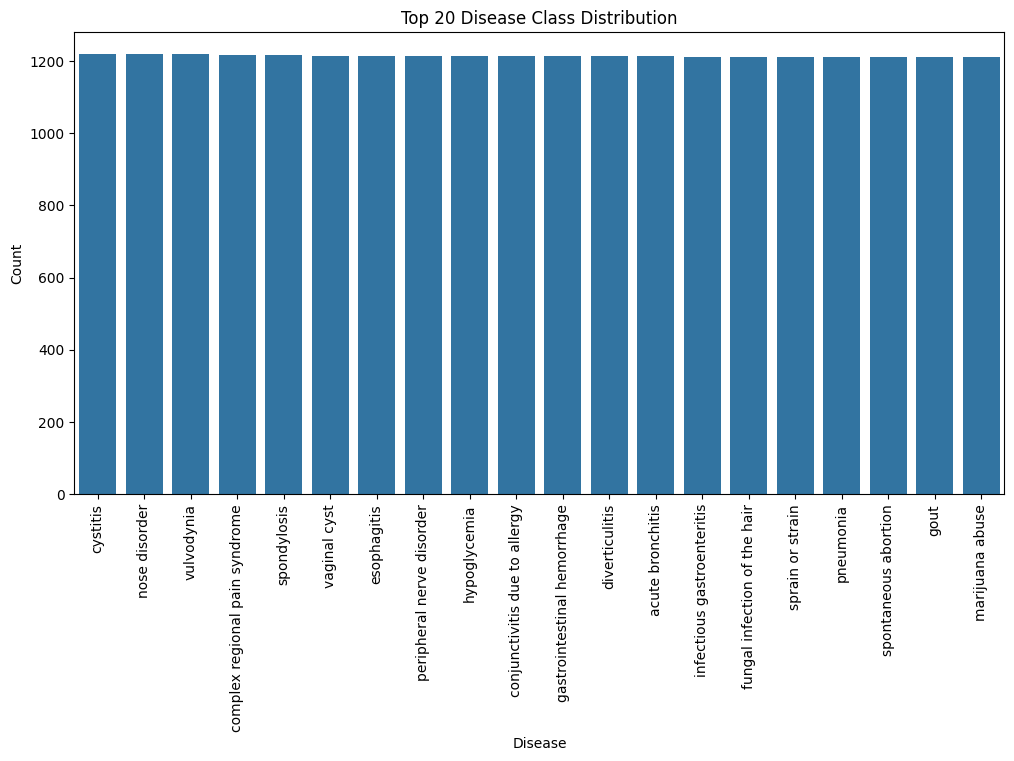


Top 10 most common symptoms:
sharp abdominal pain    32307
vomiting                27874
headache                24719
cough                   24296
sharp chest pain        24016
nausea                  23687
back pain               21809
shortness of breath     21346
fever                   20394
dizziness               17272
dtype: int64


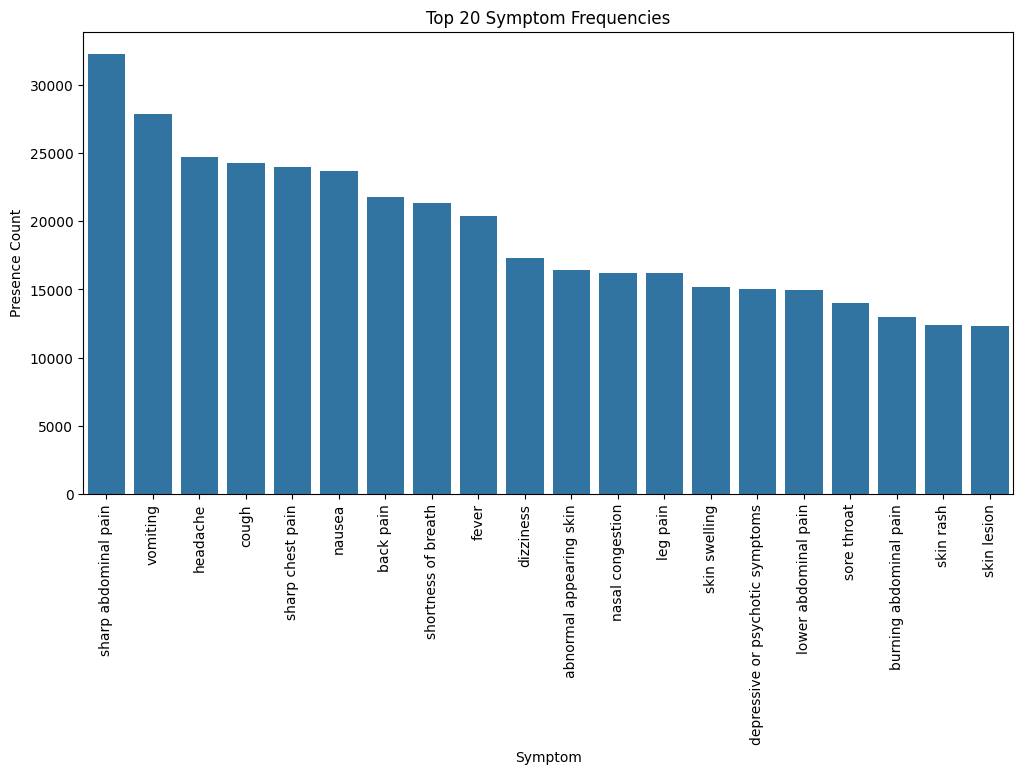

EDA complete.


In [ ]:
# Step 2: Exploratory Data Analysis (EDA)
print("\n--- EDA Section ---")
print("Data types and non-null counts:")
print(df.info())
print("\nMissing values per column (top 10):")
print(df.isnull().sum().sort_values(ascending=False).head(10))
print(f"\nNumber of unique diseases (classes): {df['diseases'].nunique()}")
print(f"Total samples: {len(df)}")

# Class distribution plot
plt.figure(figsize=(12, 6))
disease_counts = df['diseases'].value_counts()
sns.barplot(x=disease_counts.index[:20], y=disease_counts.values[:20])
plt.xticks(rotation=90)
plt.title('Top 20 Disease Class Distribution')
plt.xlabel('Disease')
plt.ylabel('Count')
plt.show()

# Symptom frequency plot
symptom_cols = [col for col in df.columns if col != 'diseases']
symptom_sums = df[symptom_cols].sum().sort_values(ascending=False)
print(f"\nTop 10 most common symptoms:")
print(symptom_sums.head(10))
plt.figure(figsize=(12, 6))
sns.barplot(x=symptom_sums.index[:20], y=symptom_sums.values[:20])
plt.xticks(rotation=90)
plt.title('Top 20 Symptom Frequencies')
plt.xlabel('Symptom')
plt.ylabel('Presence Count')
plt.show()

print("EDA complete.")

In [ ]:
# Step 3: Redundancy Removal
print("\n--- Redundancy Removal Section ---")
initial_shape = df.shape
df = df.dropna(axis=1, how='all')
df = df.loc[:, df.nunique() > 1]
print(f"After removing NaN/single-value columns: {df.shape} (removed {initial_shape[1] - df.shape[1]} columns)")

duplicates_before = len(df)
df = df.drop_duplicates()
print(f"After removing duplicates: {df.shape} (removed {duplicates_before - len(df)} rows)")

disease_counts = df['diseases'].value_counts()
rare_classes = disease_counts[disease_counts < 2].index
df = df[~df['diseases'].isin(rare_classes)]
print(f"After removing rare classes: {df.shape} (removed {len(rare_classes)} classes)")
print(f"Remaining classes: {len(df['diseases'].unique())}")


--- Redundancy Removal Section ---
After removing NaN/single-value columns: (246945, 329) (removed 49 columns)
After removing duplicates: (189647, 329) (removed 57298 rows)
After removing rare classes: (189601, 329) (removed 46 classes)
Remaining classes: 727


In [ ]:
# Step 4: Sampling
target_size = 20000  # Reduced from 50000 to prevent RAM issues
if len(df) > target_size:
    df_sampled, _ = train_test_split(df, train_size=target_size, stratify=df['diseases'], random_state=RANDOM_STATE)
    df = df_sampled
print(f"Sampled dataset shape: {df.shape}")

# Additional check: Remove any remaining rare classes (<2 samples) after sampling
disease_counts_post_sample = df['diseases'].value_counts()
rare_classes_post_sample = disease_counts_post_sample[disease_counts_post_sample < 2].index
if len(rare_classes_post_sample) > 0:
    df = df[~df['diseases'].isin(rare_classes_post_sample)]
    print(f"After removing additional rare classes post-sampling: {df.shape} (removed {len(rare_classes_post_sample)} classes)")
print(f"Final sampled dataset shape: {df.shape}")
print(f"Remaining classes: {len(df['diseases'].unique())}")

# Memory management: Delete large unused variables
del disease_counts_post_sample, rare_classes_post_sample
import gc
gc.collect()  # Force garbage collection

Sampled dataset shape: (20000, 329)
After removing additional rare classes post-sampling: (19888, 329) (removed 112 classes)
Final sampled dataset shape: (19888, 329)
Remaining classes: 546


8272

In [ ]:
# Step 5: Feature-Target Separation
X = df.drop('diseases', axis=1)
y = df['diseases']

# Step 6: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train set: {X_train.shape}, Test set: {X_test.shape}")

Train set: (15910, 328), Test set: (3978, 328)


In [ ]:
# Step 7: Baseline Benchmark Model
print("\n--- Baseline Benchmark Model ---")
# Simplified model to reduce RAM usage
baseline_model = RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE, n_jobs=2)  # Reduced estimators and parallel jobs
baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)
accuracy_baseline = accuracy_score(y_test, y_pred_baseline)
weighted_f1_baseline = f1_score(y_test, y_pred_baseline, average='weighted')
print(f"Benchmark Accuracy: {accuracy_baseline:.4f}")
print(f"Benchmark Weighted F1: {weighted_f1_baseline:.4f}")

# Memory management: Clear predictions if not needed immediately
del y_pred_baseline
gc.collect()


--- Baseline Benchmark Model ---
Benchmark Accuracy: 0.7931
Benchmark Weighted F1: 0.7860


6566

In [ ]:
# Step 8: Final Model (Advanced with Tuning and Optional SMOTE)
print("\n--- Final Model (Tuned with Optional SMOTE) ---")

# Pre-SMOTE filter: Remove classes with <6 samples from train and test sets (to allow SMOTE's default k=5)
class_counts_train = y_train.value_counts()
rare_classes_smote = class_counts_train[class_counts_train < 6].index
print(f"Removing {len(rare_classes_smote)} classes with <6 samples for SMOTE compatibility.")

# Filter train set
mask_train = ~y_train.isin(rare_classes_smote)
X_train_filtered = X_train[mask_train]
y_train_filtered = y_train[mask_train]

# Filter test set to match (for consistent evaluation)
mask_test = ~y_test.isin(rare_classes_smote)
X_test_filtered = X_test[mask_test]
y_test_filtered = y_test[mask_test]

print(f"Filtered train set: {X_train_filtered.shape}, Filtered test set: {X_test_filtered.shape}")

# Impute NaN values in X_train_filtered and X_test_filtered (SMOTE requires no NaNs)
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='mean')  # Fill NaNs with column means (suitable for numerical data)
X_train_filtered = imputer.fit_transform(X_train_filtered)
X_test_filtered = imputer.transform(X_test_filtered)  # Use same imputer for consistency
print("NaN values imputed in train and test sets.")

# Apply SMOTE for balancing on filtered data
smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)  # Default k=5; reduce to 3 if needed
X_train_smote, y_train_smote = smote.fit_resample(X_train_filtered, y_train_filtered)
print(f"After SMOTE: Train set shape: {X_train_smote.shape}")

# Hyperparameter tuning
param_dist = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
rf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=2)  # Reduced n_jobs for RAM
random_search = RandomizedSearchCV(rf, param_dist, n_iter=10, cv=3, scoring='f1_weighted', random_state=RANDOM_STATE, verbose=1)
random_search.fit(X_train_smote, y_train_smote)
final_model = random_search.best_estimator_
print(f"Best hyperparameters: {random_search.best_params_}")

# Evaluate Final Model on filtered test set
y_pred_final = final_model.predict(X_test_filtered)
accuracy_final = accuracy_score(y_test_filtered, y_pred_final)
weighted_f1_final = f1_score(y_test_filtered, y_pred_final, average='weighted')
print(f"Final Model Accuracy: {accuracy_final:.4f}")
print(f"Final Model Weighted F1: {weighted_f1_final:.4f}")
print(f"Improvement over Baseline: Accuracy +{accuracy_final - accuracy_baseline:.4f}, F1 +{weighted_f1_final - weighted_f1_baseline:.4f}")
print("\nFinal Classification Report:\n", classification_report(y_test_filtered, y_pred_final))

# Memory management: Keep filtered test sets and predictions for Cell 9; delete only SMOTE-related vars
del X_train_smote, y_train_smote  # Keep X_train_filtered, y_train_filtered, X_test_filtered, y_test_filtered, y_pred_final for Cell 9
import gc
gc.collect()


--- Final Model (Tuned with Optional SMOTE) ---
Removing 135 classes with <6 samples for SMOTE compatibility.
Filtered train set: (15560, 328), Filtered test set: (3892, 328)
NaN values imputed in train and test sets.
After SMOTE: Train set shape: (42333, 328)
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best hyperparameters: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': None}
Final Model Accuracy: 0.8309
Final Model Weighted F1: 0.8283
Improvement over Baseline: Accuracy +0.0378, F1 +0.0423

Final Classification Report:
                                                  precision    recall  f1-score   support

                               abdominal hernia       1.00      1.00      1.00         6
                                abscess of nose       0.50      1.00      0.67         3
                         abscess of the pharynx       1.00      0.67      0.80         3
                                           acne       0.67   

311

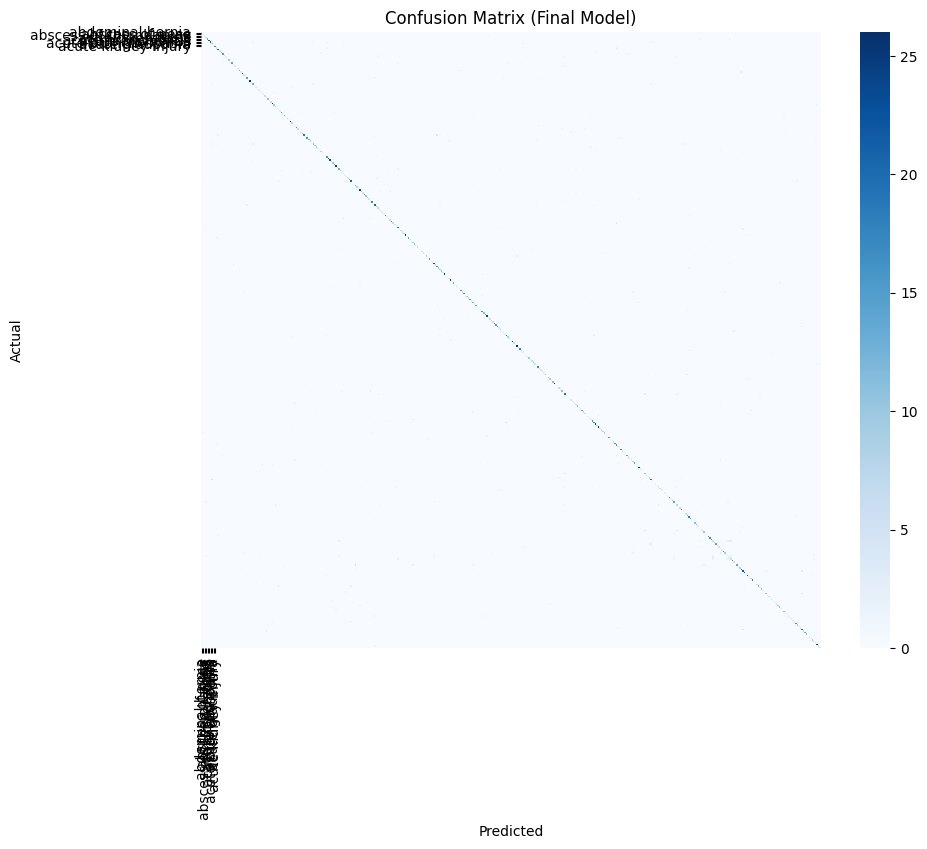

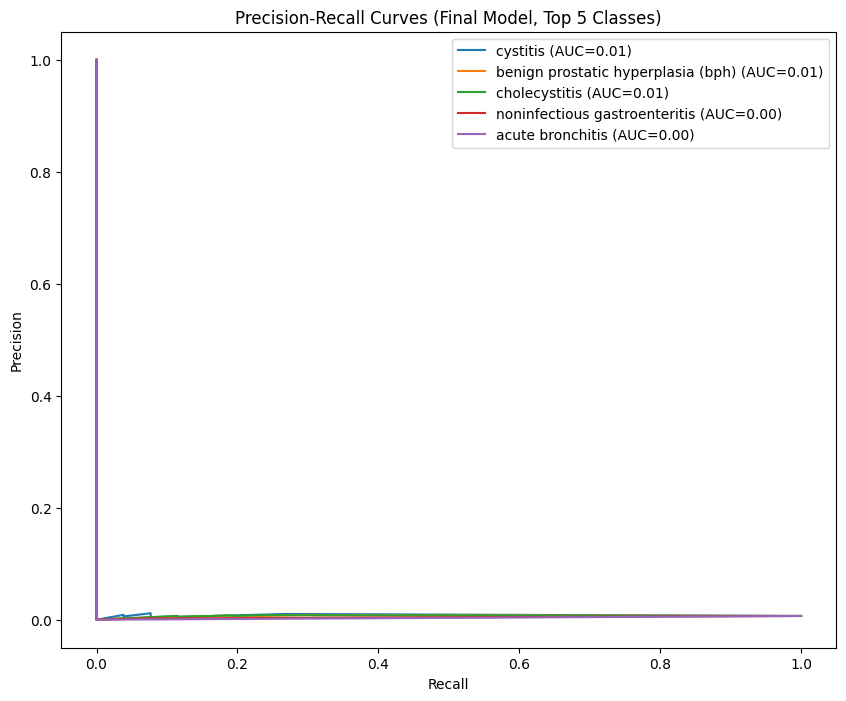

Models and metrics saved.


In [ ]:
# Step 9: Evaluation and Persistence
# Note: Using filtered test sets (y_test_filtered, X_test_filtered) to match the final model's predictions

# Confusion Matrix for Final Model
cm_final = confusion_matrix(y_test_filtered, y_pred_final)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_final, annot=False, cmap='Blues', xticklabels=final_model.classes_[:10], yticklabels=final_model.classes_[:10])
plt.title('Confusion Matrix (Final Model)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('confusion_matrix_final.png')
plt.show()

# Precision-Recall Curves for Final Model (Top 5 classes from filtered test set)
top_classes = y_test_filtered.value_counts().index[:5]  # Use filtered y_test for top classes
y_test_bin = label_binarize(y_test_filtered, classes=top_classes)
y_pred_proba_final = final_model.predict_proba(X_test_filtered)[:, :len(top_classes)]
plt.figure(figsize=(10, 8))
for i, class_name in enumerate(top_classes):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_pred_proba_final[:, i])
    pr_auc = auc(recall, precision)
    plt.plot(recall, precision, label=f'{class_name} (AUC={pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves (Final Model, Top 5 Classes)')
plt.legend()
plt.savefig('precision_recall_curves_final.png')
plt.show()

# Save models and metrics
joblib.dump(baseline_model, 'baseline_model.pkl')
joblib.dump(final_model, 'final_model.pkl')
joblib.dump(list(X.columns), 'symptom_columns.pkl')
with open('benchmark_accuracy.txt', 'w') as f:
    f.write(f"Benchmark Accuracy: {accuracy_baseline:.4f}\n")
    f.write(f"Benchmark Weighted F1: {weighted_f1_baseline:.4f}\n")
with open('final_accuracy.txt', 'w') as f:
    f.write(f"Final Accuracy: {accuracy_final:.4f}\n")
    f.write(f"Final Weighted F1: {weighted_f1_final:.4f}\n")
    f.write(f"Best Params: {random_search.best_params_}\n")
    f.write(f"Dataset Shape: {df.shape}\n")
    f.write(f"Classes: {len(df['diseases'].unique())}\n")
print("Models and metrics saved.")

In [ ]:
# Optional: Sample Prediction with Final Model
sample_symptoms = {col: 0 for col in list(X.columns)}
sample_symptoms['fever'] = 1  # Example (replace with actual symptom names from your data)
sample_input = pd.DataFrame([sample_symptoms])
predictions = final_model.predict(sample_input)
probas = final_model.predict_proba(sample_input)
top_indices = np.argsort(probas[0])[-3:][::-1]
top_diseases = final_model.classes_[top_indices]
top_probs = probas[0][top_indices]
print("\nSample Prediction (Final Model):")
for disease, prob in zip(top_diseases, top_probs):
    print(f"{disease}: {prob:.4f}")

print("\nDone! Use 'final_model.pkl' in your GUIs.")


Sample Prediction (Final Model):
orbital cellulitis: 0.0440
abscess of nose: 0.0380
common cold: 0.0352

Done! Use 'final_model.pkl' in your GUIs.


In [ ]:
# Note: If 'y_test_filtered' or 'y_pred_final' are not defined, please ensure you have run all preceding cells,
# especially the 'Step 8: Final Model (Tuned with Optional SMOTE)' cell (ID: GVDfc--AkcA-).

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("\n--- Detailed Metrics for Final Model ---")

accuracy = accuracy_score(y_test_filtered, y_pred_final)
precision = precision_score(y_test_filtered, y_pred_final, average='weighted')
recall = recall_score(y_test_filtered, y_pred_final, average='weighted')
f1 = f1_score(y_test_filtered, y_pred_final, average='weighted')

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (weighted): {precision:.4f}")
print(f"Recall (weighted): {recall:.4f}")
print(f"F1-Score (weighted): {f1:.4f}")


--- Detailed Metrics for Final Model ---
Accuracy: 0.8309
Precision (weighted): 0.8448
Recall (weighted): 0.8309
F1-Score (weighted): 0.8283
